# MOP 3231 · Task 3 — Midterm Project
Bank Marketing: predict which clients will say "yes" to a term deposit.

## Setup


In [1]:
import sys, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, joblib
warnings.filterwarnings("ignore")

SEED = 3113
print("python", sys.version.split()[0], "| sklearn", sklearn.__version__,
      "| pandas", pd.__version__, "| numpy", np.__version__, "| SEED", SEED)

python 3.13.1 | sklearn 1.7.2 | pandas 2.3.3 | numpy 2.3.4 | SEED 3113


## Loading the dataset

In [2]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

print("train shape:", train.shape)
print("test shape :", test.shape)
train.head()

train shape: (32940, 22)
test shape : (8236, 20)


,id,age,job,marital,education,default,housing,loan,contact,month,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,0,39,management,single,basic.9y,unknown,yes,no,telephone,may,...,3,999,0,nonexistent,1.1,93.994,-36.4,4.856,5191.0,no
1,1,32,admin.,single,university.degree,no,yes,no,cellular,aug,...,2,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
2,2,41,technician,married,high.school,no,no,yes,cellular,aug,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
3,3,39,admin.,married,professional.course,no,yes,yes,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,4,51,blue-collar,married,basic.9y,unknown,no,no,telephone,jun,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.864,5228.1,no


In [3]:
only_in_train = set(train.columns) - set(test.columns)
only_in_test = set(test.columns) - set(train.columns)

print("Only in train:", only_in_train)
print("Only in test :", only_in_test)

Only in train: {'y', 'duration'}
Only in test : set()


In [4]:
# target: "yes" -> 1, "no" -> 0
if train["y"].dtype == "object":
    train["y"] = train["y"].map({"yes": 1, "no": 0})

# features = all columns of test.csv except id
feature_cols = [c for c in test.columns if c != "id"]

X = train[feature_cols].copy()
y = train["y"].copy()

print("Number of features:", len(feature_cols))
print(feature_cols)

Number of features: 19
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


## Stage 1. Framing the problem

**Task.** The bank can call only 10% of clients in one campaign wave. The model gives every
client a score. The 10% of clients with the highest scores will get a call, so they should be
the clients who are most likely to say "yes" to a term deposit.

**Metric.** No need to use accuracy. Only about 11% of clients say "yes", so a model that always
says "no" already has about 89% accuracy but finds nobody.



## 2. Understanding the data

In [5]:
print(y.value_counts())

yes_rate = y.mean()
print("Share of yes:", round(yes_rate * 100, 1), "%")
print("Accuracy of a model that always says no:", round((1 - yes_rate) * 100, 1), "%")

y
0    29229
1     3711
Name: count, dtype: int64
Share of yes: 11.3 %
Accuracy of a model that always says no: 88.7 %


There are 32,940 clients in the training data. Only 3,711 of them (11.3%) said
"yes", and 29,229 said "no". A model that always answers "no" gets 88.7% accuracy, but it finds
zero clients who will say "yes". So accuracy is a bad metric here and can be misleading.

In [6]:
text_cols = X.select_dtypes(include="object").columns

for col in text_cols:
    n_unknown = (X[col] == "unknown").sum()
    if n_unknown > 0:
        print(col, ":", n_unknown, "unknown values")

if "pdays" in X.columns:
    n_999 = (X["pdays"] == 999).sum()
    print("pdays = 999:", n_999, "rows (", round(n_999 / len(X) * 100, 1), "% )")

job : 275 unknown values
marital : 64 unknown values
education : 1401 unknown values
default : 6871 unknown values
housing : 794 unknown values
loan : 794 unknown values
pdays = 999: 31694 rows ( 96.2 % )


In `pdays` the number 999 does not mean 999 days. It means "the client was not contacted in a
previous campaign". It appears in 31,694 rows (96.2%). So `pdays` is a special case: most clients have
this value.

In [7]:
changes = (X["month"] != X["month"].shift()).sum()
print("Month changes:", changes, "times in", len(X), "rows")

Month changes: 26442 times in 32940 rows


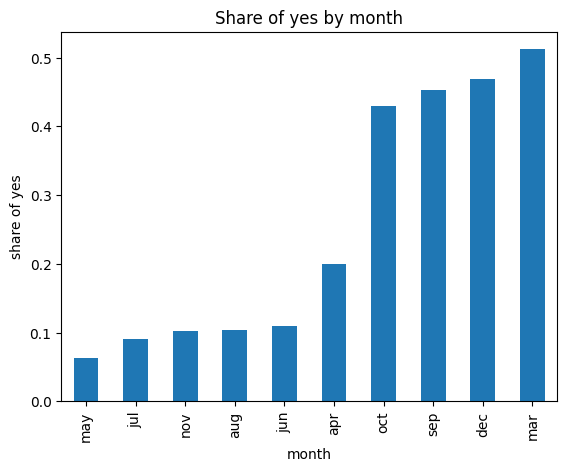

month
may    0.064
jul    0.091
nov    0.103
aug    0.104
jun    0.110
apr    0.200
oct    0.429
sep    0.453
dec    0.469
mar    0.512
Name: y, dtype: float64


In [ ]:
#graph1
month_rate = y.groupby(X["month"]).mean().sort_values()

month_rate.plot(kind="bar", title="Share of yes by month")
plt.ylabel("share of yes")
plt.show()

print(month_rate.round(3))

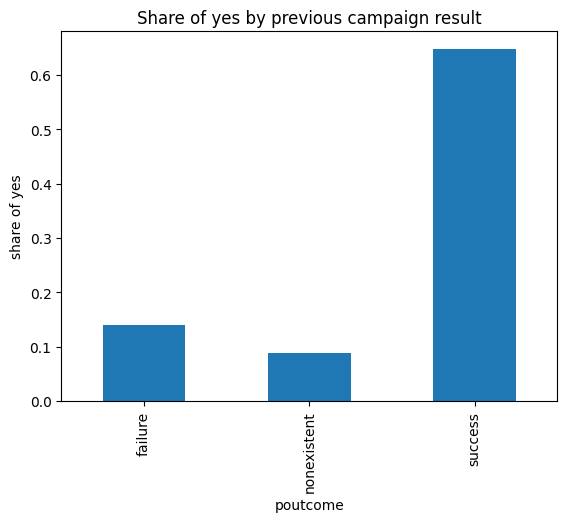

poutcome
failure        0.140
nonexistent    0.088
success        0.648
Name: y, dtype: float64


In [9]:
#graph2
poutcome_rate = y.groupby(X["poutcome"]).mean()

poutcome_rate.plot(kind="bar", title="Share of yes by previous campaign result")
plt.ylabel("share of yes")
plt.show()

print(poutcome_rate.round(3))

In [10]:
from sklearn.metrics import roc_auc_score

num_cols = X.select_dtypes(include="number").columns

rows = []
for col in num_cols:
    auc = roc_auc_score(y, X[col])
    strength = abs(auc - 0.5)   # 0 = no link, bigger = stronger link
    rows.append((col, round(auc, 3), round(strength, 3)))

table = pd.DataFrame(rows, columns=["feature", "auc", "strength"])
table.sort_values("strength", ascending=False)

,feature,auc,strength
8,nr.employed,0.250,0.250
7,euribor3m,0.255,0.245
4,emp.var.rate,0.283,0.217
3,previous,0.610,0.110
5,cons.price.idx,0.391,0.109
2,pdays,0.401,0.099
1,campaign,0.447,0.053
6,cons.conf.idx,0.542,0.042
0,age,0.491,0.009


 AUC = 0.5 means no
link with the answer. The farther from 0.5, the stronger the link. AUC below 0.5 means that
a higher value gives a lower chance of "yes".
- The strongest features are `nr.employed` (AUC 0.250), `euribor3m` (0.255) and
  `emp.var.rate` (0.283). They are economic indicators, and the link is negative: when they are
  high, fewer clients say "yes".
- `previous` (0.610), `cons.price.idx` (0.391) and `pdays` (0.401) have a weaker link.
- `campaign` (0.447), `cons.conf.idx` (0.542) and `age` (0.491) are close to 0.5, so each of
  them alone says very little.

## Stage 3. Validation design

In [11]:
from sklearn.model_selection import train_test_split

# 80% for development (CV, tuning), 20% hold-out (used only once at the end)
X_dev, X_hold, y_dev, y_hold = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,          # keep the same share of yes in both parts
    random_state=SEED
)

print("dev  :", X_dev.shape, "| share of yes:", round(y_dev.mean(), 4))
print("hold :", X_hold.shape, "| share of yes:", round(y_hold.mean(), 4))

dev  : (26352, 19) | share of yes: 0.1127
hold : (6588, 19) | share of yes: 0.1126


In [ ]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# how many clients and what share of yes in each fold
for i, (train_idx, val_idx) in enumerate(cv.split(X_dev, y_dev)):
    print("fold", i + 1,
          "| train:", len(train_idx),
          "| validation:", len(val_idx),
          "| share of yes in validation:", round(y_dev.iloc[val_idx].mean(), 4))

fold 1 | train: 21081 | validation: 5271 | share of yes in validation: 0.1127
fold 2 | train: 21081 | validation: 5271 | share of yes in validation: 0.1127
fold 3 | train: 21082 | validation: 5270 | share of yes in validation: 0.1125
fold 4 | train: 21082 | validation: 5270 | share of yes in validation: 0.1127
fold 5 | train: 21082 | validation: 5270 | share of yes in validation: 0.1127


In [ ]:
from sklearn.model_selection import cross_validate

RESULTS = {}   

def evaluate(model, name):
    scores = cross_validate(
        model, X_dev, y_dev,
        cv=cv,
        scoring=["roc_auc", "average_precision"],
        n_jobs=-1
    )
    auc = scores["test_roc_auc"]
    ap = scores["test_average_precision"]
    RESULTS[name] = auc     # save for comparison later

    print(name)
    print("  ROC-AUC          :", round(auc.mean(), 4), "+/-", round(auc.std(), 4))
    print("  Average precision:", round(ap.mean(), 4), "+/-", round(ap.std(), 4))
    return scores

## Stage 4. Preprocessing inside a pipeline

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone

# text columns
cat_cols = X.select_dtypes(include="object").columns.tolist()

# number columns (pdays is special, so I take it out)
num_cols = [c for c in X.select_dtypes(include="number").columns if c != "pdays"]

print("text columns  :", cat_cols)
print("number columns:", num_cols)

text columns  : ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
number columns: ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


In [15]:
def make_prep(unknown="category"):
    """unknown = 'category' -> keep 'unknown' as a normal category
       unknown = 'impute'   -> replace 'unknown' with the most frequent value"""

    # numbers: only scaling
    num_part = Pipeline([("scaler", StandardScaler())])

    # pdays: 999 -> median + extra column "was 999" (0/1), then scaling
    pdays_part = Pipeline([
        ("imputer", SimpleImputer(missing_values=999, strategy="median", add_indicator=True)),
        ("scaler", StandardScaler())
    ])

    # text: one-hot encoding 
    cat_steps = [("onehot", OneHotEncoder(handle_unknown="ignore"))]
    if unknown == "impute":
        cat_steps.insert(0, ("imputer", SimpleImputer(missing_values="unknown",
                                                      strategy="most_frequent")))
    cat_part = Pipeline(cat_steps)

    return ColumnTransformer([
        ("num", num_part, num_cols),
        ("pdays", pdays_part, ["pdays"]),
        ("cat", cat_part, cat_cols),
    ])


def make_pipe(clf, unknown="category"):
    return Pipeline([("prep", make_prep(unknown)), ("clf", clf)])


def lr(**kwargs):
    return LogisticRegression(max_iter=2000, random_state=SEED, **kwargs)

In [16]:
# For every fold I fit the pipeline on the training part only
# and print what the scaler learned (mean of the first number column).
for i, (train_idx, val_idx) in enumerate(cv.split(X_dev, y_dev)):
    pipe = clone(make_pipe(lr()))
    pipe.fit(X_dev.iloc[train_idx], y_dev.iloc[train_idx])

    scaler = pipe.named_steps["prep"].named_transformers_["num"].named_steps["scaler"]
    print("fold", i + 1, "| mean of", num_cols[0], "learned on train part:", round(scaler.mean_[0], 4))

fold 1 | mean of age learned on train part: 40.048
fold 2 | mean of age learned on train part: 40.0877
fold 3 | mean of age learned on train part: 40.0069
fold 4 | mean of age learned on train part: 40.0871
fold 5 | mean of age learned on train part: 40.0521


**Evidence.** In the output, the mean age learned by the scaler is different in every fold: from
40.007 (fold 3) to 40.088 (fold 2). The differences are small, but they show that the scaler is
fitted again on each training part. If it had seen all the data, the number would be the same
in every fold.

In [17]:
r1 = evaluate(make_pipe(lr(), unknown="category"), "LogReg | unknown = own category")
r2 = evaluate(make_pipe(lr(), unknown="impute"),   "LogReg | unknown = most frequent value")

LogReg | unknown = own category
  ROC-AUC          : 0.7971 +/- 0.0067
  Average precision: 0.4562 +/- 0.0217
LogReg | unknown = most frequent value
  ROC-AUC          : 0.7973 +/- 0.0064
  Average precision: 0.4571 +/- 0.0218


**Comparison of `unknown`.**

| Option | ROC-AUC (mean ± std) | Average precision (mean ± std) |
|---|---|---|
| `unknown` as its own category | 0.7971 ± 0.0067 | 0.4562 ± 0.0217 |
| `unknown` replaced by the most frequent value | 0.7973 ± 0.0064 | 0.4571 ± 0.0218 |

**What the numbers mean.** A ROC-AUC of 0.797 means that if I take one client who said "yes" and
one who said "no", the model gives a higher score to the "yes" client in about 80% of cases.
A random model gets 0.5. An average precision of 0.456 is about 4 times higher than the share of
"yes" in the data (0.113), which is the value of a random model.

## Stage 5. Baselines

In [18]:
UNK = "category"

In [19]:
def evaluate_with_accuracy(model, name):
    scores = cross_validate(
        model, X_dev, y_dev,
        cv=cv,
        scoring=["accuracy", "roc_auc", "average_precision"],
        n_jobs=-1
    )
    RESULTS[name] = scores["test_roc_auc"]   

    print(name)
    for metric in ["accuracy", "roc_auc", "average_precision"]:
        values = scores["test_" + metric]
        print("  ", metric.ljust(18), round(values.mean(), 4), "+/-", round(values.std(), 4))
    return scores

In [22]:
#baseline 1
from sklearn.dummy import DummyClassifier

dummy_pipe = make_pipe(DummyClassifier(strategy="most_frequent"), unknown=UNK)
dummy_scores = evaluate_with_accuracy(dummy_pipe, "Baseline: always no")

Baseline: always no
   accuracy           0.8873 +/- 0.0001
   roc_auc            0.5 +/- 0.0
   average_precision  0.1127 +/- 0.0001


In [23]:
#baseline 2
lr_pipe = make_pipe(lr(), unknown=UNK)
lr_scores = evaluate_with_accuracy(lr_pipe, "Baseline: LogReg")

Baseline: LogReg
   accuracy           0.8994 +/- 0.0031
   roc_auc            0.7971 +/- 0.0067
   average_precision  0.4562 +/- 0.0217


In [24]:
rows = []
for name, scores in [("Always no", dummy_scores), ("LogReg", lr_scores)]:
    rows.append((
        name,
        round(scores["test_accuracy"].mean(), 4),
        round(scores["test_roc_auc"].mean(), 4),
        round(scores["test_roc_auc"].std(), 4),
        round(scores["test_average_precision"].mean(), 4),
        round(scores["test_average_precision"].std(), 4),
    ))

baseline_table = pd.DataFrame(rows, columns=[
    "model", "accuracy", "AUC mean", "AUC std", "AP mean", "AP std"])
baseline_table

,model,accuracy,AUC mean,AUC std,AP mean,AP std
0,Always no,0.8873,0.5000,0.0000,0.1127,0.0001
1,LogReg,0.8994,0.7971,0.0067,0.4562,0.0217


**Baseline 1: always "no".** Accuracy is 0.8873, but ROC-AUC is 0.5000 (random) and average
precision is 0.1127 (the share of "yes"). The model finds no "yes" clients, so accuracy is
misleading here. I use ROC-AUC and average precision instead.

**Baseline 2: logistic regression.** Accuracy is 0.8994, only 1.2 points higher than "always no".
But ROC-AUC is 0.7971 ± 0.0067 and average precision is 0.4562 ± 0.0217, about 4 times higher than
random. So accuracy hides the real difference.

**The bar for later models.** Every model must beat ROC-AUC 0.7971. The fold std is about 0.007,
so a model is better only if the difference is bigger than this noise.

## Stage 6. Compare models and tune

In [25]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

In [26]:
# Logistic regression: without and with class weights
evaluate(make_pipe(lr(), unknown=UNK), "LR default")
evaluate(make_pipe(lr(class_weight="balanced"), unknown=UNK), "LR balanced")

# Random forest: without and with class weights
rf_default = RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                    n_jobs=-1, random_state=SEED)
rf_balanced = RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                     class_weight="balanced_subsample",
                                     n_jobs=-1, random_state=SEED)
evaluate(make_pipe(rf_default, unknown=UNK), "RF default")
evaluate(make_pipe(rf_balanced, unknown=UNK), "RF balanced")

# KNN (it has no class_weight)
evaluate(make_pipe(KNeighborsClassifier(n_neighbors=50), unknown=UNK), "KNN k=50")

LR default
  ROC-AUC          : 0.7971 +/- 0.0067
  Average precision: 0.4562 +/- 0.0217
LR balanced
  ROC-AUC          : 0.7977 +/- 0.0069
  Average precision: 0.4512 +/- 0.0214
RF default
  ROC-AUC          : 0.8011 +/- 0.0074
  Average precision: 0.475 +/- 0.0168
RF balanced
  ROC-AUC          : 0.8023 +/- 0.0077
  Average precision: 0.4734 +/- 0.0151
KNN k=50
  ROC-AUC          : 0.782 +/- 0.0059
  Average precision: 0.4273 +/- 0.0172


{'fit_time': array([0.19595146, 0.19774413, 0.184834  , 0.18677616, 0.17644858]),
 'score_time': array([2.47868395, 2.37802958, 2.44218683, 2.44626522, 2.39740968]),
 'test_roc_auc': array([0.78298   , 0.77591178, 0.78824851, 0.77443058, 0.78835997]),
 'test_average_precision': array([0.42443349, 0.42867636, 0.4131422 , 0.41137362, 0.45908597])}

Without class weights / with class weights (ROC-AUC): LR 0.7971 / 0.7977,
RF 0.8011 / 0.8023. The differences (0.0006 and 0.0012) are much smaller than the fold std
(about 0.007), so they are noise. Average precision also did not improve (LR 0.4562 → 0.4512).
So handling the imbalance does not help here. 


In [27]:
searches = {}

# 1) Logistic regression
searches["LR"] = GridSearchCV(
    make_pipe(lr(), unknown=UNK),
    param_grid={"clf__C": [0.01, 0.1, 1, 10],
                "clf__class_weight": [None, "balanced"]},
    scoring="roc_auc", cv=cv, n_jobs=-1
)

# 2) KNN
searches["KNN"] = GridSearchCV(
    make_pipe(KNeighborsClassifier(), unknown=UNK),
    param_grid={"clf__n_neighbors": [25, 50, 100],
                "clf__weights": ["uniform", "distance"]},
    scoring="roc_auc", cv=cv, n_jobs=-1
)

# 3) Random forest (random search, 10 combinations)
searches["RF"] = RandomizedSearchCV(
    make_pipe(RandomForestClassifier(n_jobs=-1, random_state=SEED), unknown=UNK),
    param_distributions={"clf__n_estimators": [200, 400],
                         "clf__max_depth": [6, 10, 16, None],
                         "clf__min_samples_leaf": [1, 5, 20],
                         "clf__max_features": ["sqrt", 0.3],
                         "clf__class_weight": [None, "balanced_subsample"]},
    n_iter=10, scoring="roc_auc", cv=cv, n_jobs=-1, random_state=SEED
)

for name, search in searches.items():
    search.fit(X_dev, y_dev)
    i = search.best_index_
    print(name)
    print("  best params:", search.best_params_)
    print("  CV ROC-AUC :", round(search.cv_results_["mean_test_score"][i], 4),
          "+/-", round(search.cv_results_["std_test_score"][i], 4))

LR
  best params: {'clf__C': 0.1, 'clf__class_weight': 'balanced'}
  CV ROC-AUC : 0.7979 +/- 0.0068
KNN
  best params: {'clf__n_neighbors': 100, 'clf__weights': 'uniform'}
  CV ROC-AUC : 0.79 +/- 0.0081
RF
  best params: {'clf__n_estimators': 200, 'clf__min_samples_leaf': 20, 'clf__max_features': 0.3, 'clf__max_depth': 10, 'clf__class_weight': 'balanced_subsample'}
  CV ROC-AUC : 0.8083 +/- 0.0067


Search space: LR: C in [0.01, 0.1, 1, 10], class_weight in [None, balanced].
KNN: k in [25, 50, 100], weights in [uniform, distance].
RF (10 random combinations): n_estimators [200, 400], max_depth [6, 10, 16, None],
min_samples_leaf [1, 5, 20], max_features [sqrt, 0.3], class_weight [None, balanced_subsample].

In [28]:
# ROC-AUC of every fold for the best setting of each model
fold_scores = {}
for name, search in searches.items():
    i = search.best_index_
    fold_scores[name] = np.array(
        [search.cv_results_["split" + str(k) + "_test_score"][i] for k in range(5)])

for name, values in fold_scores.items():
    print(name, "| mean:", round(values.mean(), 4), "| std:", round(values.std(), 4))

# compare every pair on the same folds
names = list(fold_scores)
for a in range(len(names)):
    for b in range(a + 1, len(names)):
        diff = fold_scores[names[a]] - fold_scores[names[b]]
        if abs(diff.mean()) < diff.std():
            verdict = "INSIDE the noise"
        else:
            verdict = "bigger than the noise"
        print(names[a], "-", names[b], "| mean diff:", round(diff.mean(), 4),
              "| std of diff:", round(diff.std(), 4), "->", verdict)

# the best model by mean score
best_name = max(fold_scores, key=lambda n: fold_scores[n].mean())
best_search = searches[best_name]
print("Best by mean ROC-AUC:", best_name)

LR | mean: 0.7979 | std: 0.0068
KNN | mean: 0.79 | std: 0.0081
RF | mean: 0.8083 | std: 0.0067
LR - KNN | mean diff: 0.0079 | std of diff: 0.009 -> INSIDE the noise
LR - RF | mean diff: -0.0105 | std of diff: 0.005 -> bigger than the noise
KNN - RF | mean diff: -0.0183 | std of diff: 0.0047 -> bigger than the noise
Best by mean ROC-AUC: RF


- LR vs KNN: difference 0.0079, std of difference 0.009 → inside the noise.
- RF vs LR: difference 0.0105, std 0.005 → bigger than the noise.
- RF vs KNN: difference 0.0183, std 0.0047 → bigger than the noise.


## Stage 7. Final evaluation on the hold-out (used once)

In [29]:
from sklearn.metrics import roc_auc_score, average_precision_score

# best pipeline from Stage 6, fitted on the development part only
final_dev = clone(best_search.best_estimator_)
final_dev.fit(X_dev, y_dev)

# score = probability of "yes" for every client in the hold-out
hold_scores = final_dev.predict_proba(X_hold)[:, 1]

auc = roc_auc_score(y_hold, hold_scores)
ap = average_precision_score(y_hold, hold_scores)

print("Hold-out ROC-AUC          :", round(auc, 4))
print("Hold-out average precision:", round(ap, 4))
print("Share of yes in hold-out  :", round(y_hold.mean(), 4))

Hold-out ROC-AUC          : 0.7842
Hold-out average precision: 0.4619
Share of yes in hold-out  : 0.1126


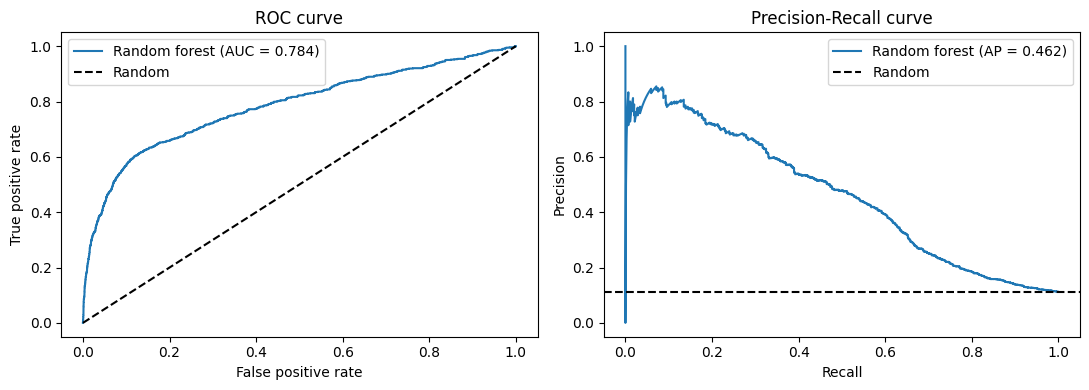

In [30]:
from sklearn.metrics import roc_curve, precision_recall_curve

fpr, tpr, _ = roc_curve(y_hold, hold_scores)
prec_curve, rec_curve, _ = precision_recall_curve(y_hold, hold_scores)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# ROC curve
axes[0].plot(fpr, tpr, label="Random forest (AUC = " + str(round(auc, 3)) + ")")
axes[0].plot([0, 1], [0, 1], "k--", label="Random")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curve")
axes[0].legend()

# Precision-Recall curve
axes[1].plot(rec_curve, prec_curve, label="Random forest (AP = " + str(round(ap, 3)) + ")")
axes[1].axhline(y_hold.mean(), color="k", linestyle="--", label="Random")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curve")
axes[1].legend()

plt.tight_layout()
plt.show()

**ROC curve.** The curve is clearly above the random line. For example, when we wrongly
include about 20% of the "no" clients, we find about 65% of the "yes" clients. AUC = 0.784.

**Precision-Recall curve.** At low recall (about 0.1-0.2) the precision is about 0.8, so the
clients with the highest scores almost always say "yes". When we take more clients, precision
goes down. At recall 0.46 it is about 0.5, which is our 10% rule point. The random level is 0.113,
and the curve stays above it. AP = 0.462. The sharp peak at the very beginning is noise,
because it has only a few clients.

In [ ]:
from sklearn.metrics import precision_score, recall_score, confusion_matrix

#  10% of the clients
n_calls = int(np.ceil(0.10 * len(hold_scores)))

# cutoff = the score of the n_calls-th best client
cutoff = np.sort(hold_scores)[::-1][n_calls - 1]
hold_pred = (hold_scores >= cutoff).astype(int)

precision = precision_score(y_hold, hold_pred)
recall = recall_score(y_hold, hold_pred)
lift = precision / y_hold.mean()      

tn, fp, fn, tp = confusion_matrix(y_hold, hold_pred).ravel()

print("Cutoff            :", round(cutoff, 4))
print("Clients called    :", hold_pred.sum(), "of", len(hold_pred))
print("Precision         :", round(precision, 3))
print("Recall            :", round(recall, 3))
print("Lift over random  :", round(lift, 2), "x")
print()
print("Confusion matrix")
print("  Called, said yes (TP)      :", tp)
print("  Called, said no (FP)       :", fp)
print("  Not called, would say yes (FN):", fn)
print("  Not called, would say no (TN) :", tn)

Cutoff            : 0.7838
Clients called    : 659 of 6588
Precision         : 0.513
Recall            : 0.456
Lift over random  : 4.55 x

Confusion matrix
  Called, said yes (TP)      : 338
  Called, said no (FP)       : 321
  Not called, would say yes (FN): 404
  Not called, would say no (TN) : 5525
